# Exploratory analysis of a Portuguese bank’s phone marketing campaign.

Goal: find which client and campaign characteristics are linked to subscribing to a term deposit.

In [58]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

data = pd.read_csv('cleaned_bank_marketing.csv')
data

,age,job,marital_status,education,credit_default,housing_loan,personal_loan,contact_type,month,day_of_week,current_campaign_contacts,days_since_previous_contact,previous_campaign_contacts,previous_campaign_outcome,subscribed,previously_contacted
0,56,housemaid,married,basic education - 4 years,no,no,no,telephone,may,monday,1,NaN,0,nonexistent,no,False
1,57,services,married,high school / secondary education,unknown,no,no,telephone,may,monday,1,NaN,0,nonexistent,no,False
2,37,services,married,high school / secondary education,no,yes,no,telephone,may,monday,1,NaN,0,nonexistent,no,False
3,40,admin,married,basic education - 6 years,no,no,no,telephone,may,monday,1,NaN,0,nonexistent,no,False
4,56,services,married,high school / secondary education,no,no,yes,telephone,may,monday,1,NaN,0,nonexistent,no,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional / vocational course,no,yes,no,cellular,november,friday,1,NaN,0,nonexistent,yes,False
41184,46,blue-collar,married,professional / vocational course,no,no,no,cellular,november,friday,1,NaN,0,nonexistent,no,False
41185,56,retired,married,university degree,no,yes,no,cellular,november,friday,2,NaN,0,nonexistent,no,False
41186,44,technician,married,professional / vocational course,no,no,no,cellular,november,friday,1,NaN,0,nonexistent,yes,False


In [59]:
# How many total clients subscribed vs did not subscribe?
data['subscribed'].value_counts()

subscribed
no     36548
yes     4640
Name: count, dtype: int64

In [60]:
# How many total clients subscribed vs did not subscribe?(percentages)

total_clients_contact = (data['subscribed'].value_counts() / len(data)) * 100
total_clients_contact.round(2)

subscribed
no     88.73
yes    11.27
Name: count, dtype: float64

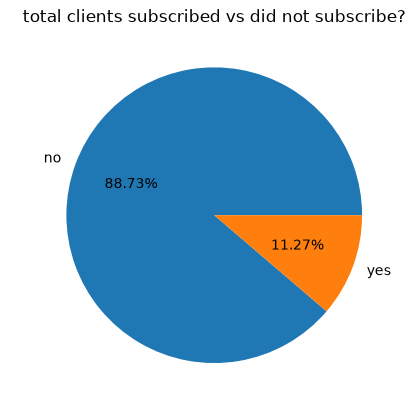

In [61]:
total_clients_contact.plot(kind='pie',autopct='%1.2f%%')
plt.title('total clients subscribed vs did not subscribe?')
plt.ylabel(' ')
plt.show()

In [62]:
baseline = ((data['subscribed'] == 'yes').mean() * 100).round(1)
baseline

np.float64(11.3)

In [63]:
def subscribing_by(df,column, sort=True):
    counts = pd.crosstab(df[column],df['subscribed'])
    counts['total'] = counts.sum(axis=1)
    counts['rate'] = ((counts['yes'] / counts['total']) * 100 ).round(1)
    counts['vs_baseline'] = (counts['rate'] - baseline).round(1)
    if sort:
       counts = counts.sort_values('rate',ascending=False)
    return counts[['total','yes','rate','vs_baseline']]

data['age_group'] = pd.cut(data['age'],
                           bins=[16, 29, 39, 49, 59, 100],
                           labels=['17-29', '30-39', '40-49', '50-59', '60+'])

subscribing_by(data,'job')

subscribed,total,yes,rate,vs_baseline
job,,,,
student,875,275,31.4,20.1
retired,1720,434,25.2,13.9
unemployed,1014,144,14.2,2.9
admin,10422,1352,13.0,1.7
management,2924,328,11.2,-0.1
unknown,330,37,11.2,-0.1
technician,6743,730,10.8,-0.5
self-employed,1421,149,10.5,-0.8
housemaid,1060,106,10.0,-1.3


In [64]:
# Which job categories had the most clients contacted overall?
total_contacted_per_job = data.groupby('job')['subscribed'].count()
total_contacted_per_job = total_contacted_per_job.sort_values(ascending=False)
total_contacted_per_job

job
admin            10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: subscribed, dtype: int64

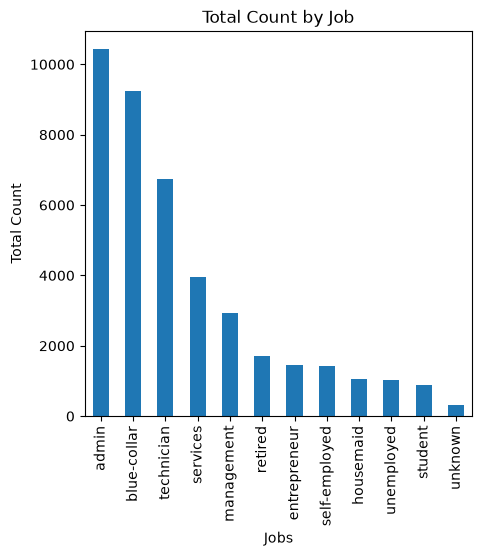

In [65]:

total_contacted_per_job.plot(kind='bar',figsize=(5,5))
plt.ylabel('Total Count')
plt.xlabel('Jobs')
plt.title("Total Count by Job")
plt.show()

In [66]:
# For each job category, how many subscribed and how many did not?

job_subscription_count = pd.crosstab(data['job'],data['subscribed'])
job_subscription_count

subscribed,no,yes
job,,
admin,9070,1352
blue-collar,8616,638
entrepreneur,1332,124
housemaid,954,106
management,2596,328
retired,1286,434
self-employed,1272,149
services,3646,323
student,600,275


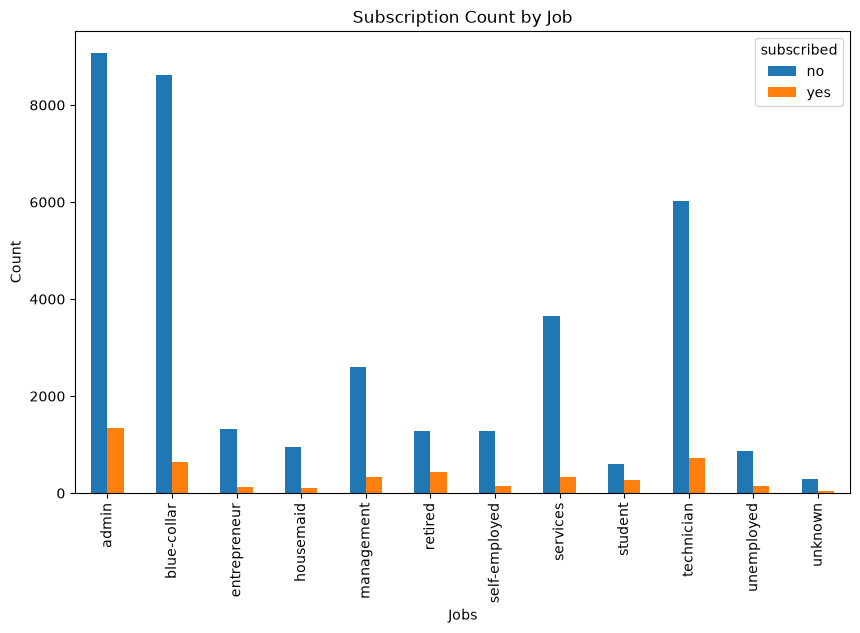

In [67]:
job_subscription_count.plot(kind='bar', figsize=(10,6))
plt.ylabel('Count')
plt.xlabel('Jobs')
plt.title("Subscription Count by Job")
plt.show()

In [68]:
# Of the clients in each job category, what percentage subscribed?
job_subscription_rate = pd.crosstab(data['job'],
                                    data['subscribed'],
                                    normalize='index'
                                   )['yes'] * 100
job_subscription_rate

job
admin            12.972558
blue-collar       6.894316
entrepreneur      8.516484
housemaid        10.000000
management       11.217510
retired          25.232558
self-employed    10.485574
services          8.138070
student          31.428571
technician       10.826042
unemployed       14.201183
unknown          11.212121
Name: yes, dtype: float64

In [69]:
# Does subscription rate differ across job categories?

sorted_job_subscription_rate =job_subscription_rate.sort_values( ascending=False)
sorted_job_subscription_rate

job
student          31.428571
retired          25.232558
unemployed       14.201183
admin            12.972558
management       11.217510
unknown          11.212121
technician       10.826042
self-employed    10.485574
housemaid        10.000000
entrepreneur      8.516484
services          8.138070
blue-collar       6.894316
Name: yes, dtype: float64

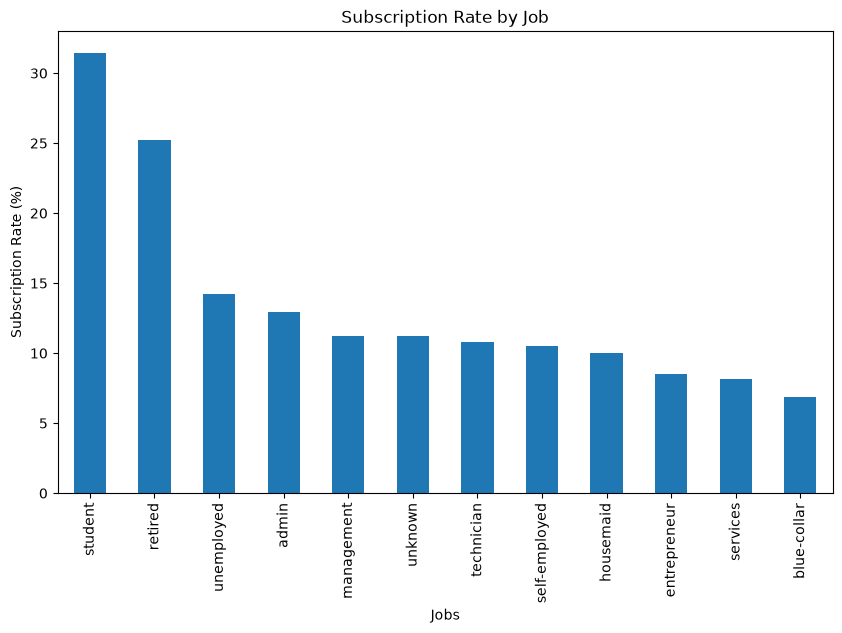

In [70]:
sorted_job_subscription_rate.plot(kind='bar', figsize=(10,6))
plt.ylabel('Subscription Rate (%)')
plt.xlabel('Jobs')
plt.title("Subscription Rate by Job")
plt.show()

### Job Analysis and how the percentages differ

Students subscribe at 31.4%, almost three times the 11.3% baseline, based on 875 people. Blue-collar workers subscribe at only 6.9%, below the baseline, even though they were the 2nd largest group called (9,254 people). The bank spent its second-largest share of calls on the group least likely to say yes.

In [71]:
# For each marital_status category, how many subscribed and how many did not?
marital_status_sub_count = pd.crosstab(data['marital_status'],data['subscribed'])
marital_status_sub_count

subscribed,no,yes
marital_status,,
divorced,4136,476
married,22396,2532
single,9948,1620
unknown,68,12


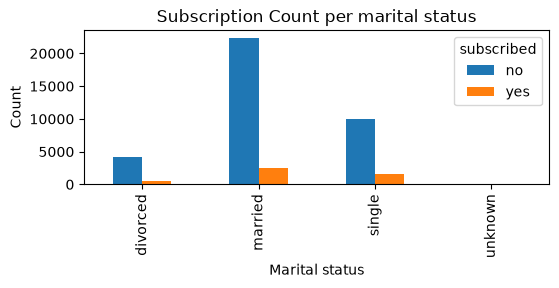

In [72]:
marital_status_sub_count.plot(kind='bar',figsize=(6,2))
plt.ylabel('Count')
plt.xlabel('Marital status')
plt.title('Subscription Count per marital status')
plt.show()

In [73]:
marital_status_total_count = data.groupby('marital_status')['subscribed'].count()
marital_status_total_count

marital_status
divorced     4612
married     24928
single      11568
unknown        80
Name: subscribed, dtype: int64

In [74]:
marital_status_sub_rate = pd.crosstab(data['marital_status'],
                                      data['subscribed'],
                                      normalize='index')['yes'] * 100
sorted_marital_status_sub_rate = marital_status_sub_rate.sort_values(ascending=False)
sorted_marital_status_sub_rate

marital_status
unknown     15.000000
single      14.004149
divorced    10.320902
married     10.157253
Name: yes, dtype: float64

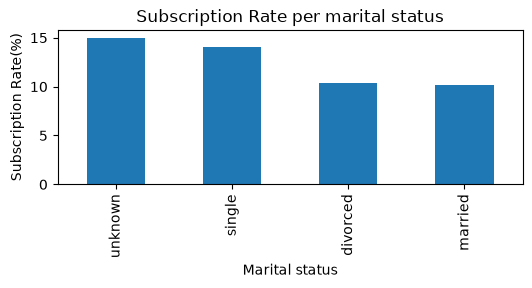

In [75]:
sorted_marital_status_sub_rate.plot(kind='bar',figsize=(6,2))
plt.ylabel('Subscription Rate(%)')
plt.xlabel('Marital status')
plt.title('Subscription Rate per marital status')
plt.show()

In [76]:
subscribing_by(data,'marital_status')

subscribed,total,yes,rate,vs_baseline
marital_status,,,,
unknown,80,12,15.0,3.7
single,11568,1620,14.0,2.7
divorced,4612,476,10.3,-1.0
married,24928,2532,10.2,-1.1


In [77]:
subscribing_by(data[data['marital_status'] == 'single'],'job')

subscribed,total,yes,rate,vs_baseline
job,,,,
student,824,264,32.0,20.7
unknown,74,15,20.3,9.0
unemployed,251,48,19.1,7.8
admin,3875,566,14.6,3.3
self-employed,379,51,13.5,2.2
housemaid,119,16,13.4,2.1
retired,93,12,12.9,1.6
management,501,63,12.6,1.3
technician,2287,279,12.2,0.9


In [78]:
subscribing_by(data[data['marital_status'] == 'single'],'age_group')

subscribed,total,yes,rate,vs_baseline
age_group,,,,
60+,41,11,26.8,15.5
17-29,3892,751,19.3,8.0
30-39,5769,684,11.9,0.6
50-59,421,44,10.5,-0.8
40-49,1445,130,9.0,-2.3


### Marital Status Conclusion

Single people subscribe at 14.0%, which is 2.7 points above the 11.3% baseline. At the same age, single people beat everyone else by only 1–3 points (17–29: 19.3% vs. 16.3%; 30–39: 11.9% vs. 10.1%). So most of the lift comes from single people being younger and more often students, not from being single.

In [79]:
month_subscirption_count = pd.crosstab(data['month'],data['subscribed'])
month_subscirption_count

subscribed,no,yes
month,,
april,2093,539
august,5523,655
december,93,89
july,6525,649
june,4759,559
march,270,276
may,12883,886
november,3685,416
october,403,315


In [80]:
total_month_subscription = data.groupby('month')['subscribed'].count()
sorted_total_month_subscription = total_month_subscription.sort_values(ascending=False)
sorted_total_month_subscription

month
may          13769
july          7174
august        6178
june          5318
november      4101
april         2632
october        718
september      570
march          546
december       182
Name: subscribed, dtype: int64

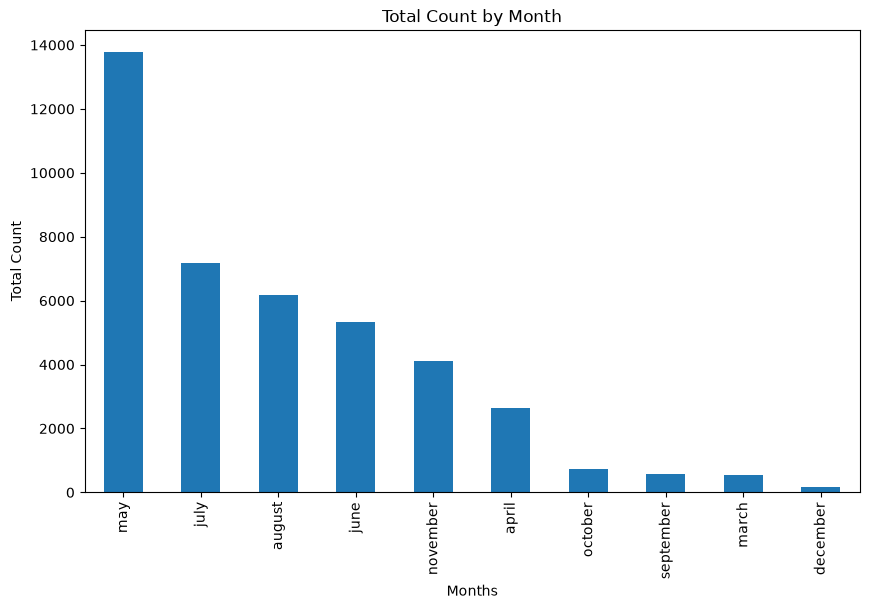

In [81]:
sorted_total_month_subscription.plot(kind='bar', figsize=(10,6))
plt.ylabel('Total Count')
plt.xlabel('Months')
plt.title('Total Count by Month')
plt.show()

In [82]:
month_subscription_rate = pd.crosstab(data['month'],
                                    data['subscribed'],
                                    normalize='index'
                                   ) ['yes'] * 100
sorted_month_subscription_rate = month_subscription_rate.sort_values(ascending=False)
sorted_month_subscription_rate

month
march        50.549451
december     48.901099
september    44.912281
october      43.871866
april        20.478723
august       10.602137
june         10.511470
november     10.143867
july          9.046557
may           6.434745
Name: yes, dtype: float64

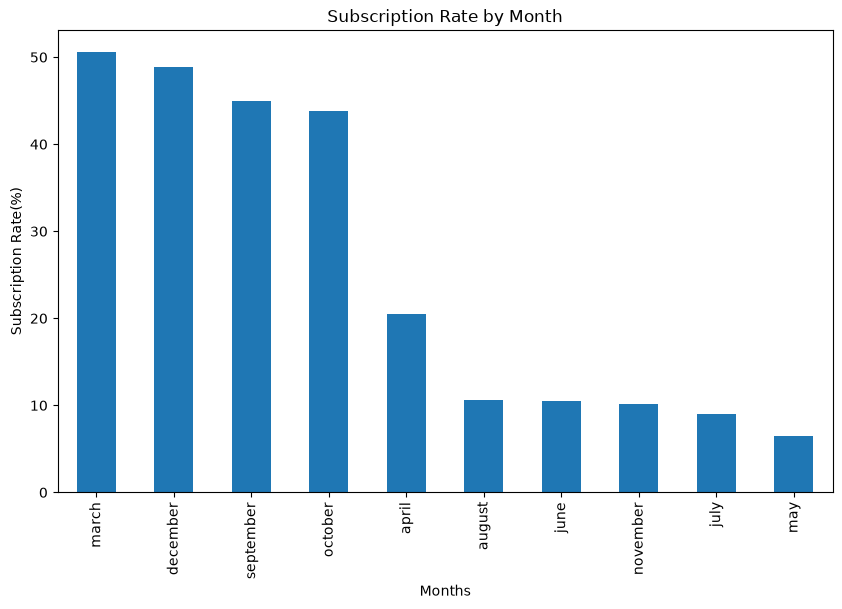

In [83]:
sorted_month_subscription_rate.plot(kind='bar', figsize=(10,6))
plt.ylabel('Subscription Rate(%)')
plt.xlabel('Months')
plt.title('Subscription Rate by Month')
plt.show()

In [84]:
pivot_table = data.pivot_table(index='month',
                              values=['subscribed'],
                              aggfunc={'subscribed':'count'})
pivot_table['subscription_rate'] = sorted_month_subscription_rate
pivot_table = pivot_table.rename(columns={'subscribed':'contacted'})
pivot_table.sort_values('subscription_rate',ascending=False)

,contacted,subscription_rate
month,,
march,546,50.549451
december,182,48.901099
september,570,44.912281
october,718,43.871866
april,2632,20.478723
august,6178,10.602137
june,5318,10.511470
november,4101,10.143867
july,7174,9.046557


In [85]:
subscribing_by(data, 'previous_campaign_outcome')

subscribed,total,yes,rate,vs_baseline
previous_campaign_outcome,,,,
success,1373,894,65.1,53.8
failure,4252,605,14.2,2.9
nonexistent,35563,3141,8.8,-2.5


In [86]:
(pd.crosstab(data['month'], data['previous_campaign_outcome'], normalize='index') * 100).round(1)

previous_campaign_outcome,failure,nonexistent,success
month,,,
april,24.6,71.2,4.2
august,4.1,92.6,3.3
december,21.4,53.8,24.7
july,1.7,96.8,1.5
june,3.2,94.1,2.7
march,17.9,67.2,14.8
may,12.9,85.4,1.7
november,20.5,75.5,4.0
october,23.4,57.7,18.9


In [87]:
# whats the rate from people who have never been contacted ? 
subscribing_by(data[data['previous_campaign_outcome'] == 'nonexistent'], 'month', sort=False)

subscribed,total,yes,rate,vs_baseline
month,,,,
april,1874,397,21.2,9.9
august,5719,441,7.7,-3.6
december,98,46,46.9,35.6
july,6946,518,7.5,-3.8
june,5003,410,8.2,-3.1
march,367,174,47.4,36.1
may,11760,643,5.5,-5.8
november,3097,249,8.0,-3.3
october,414,162,39.1,27.8


### Month Conclusion

The busiest month, May, had 13,769 calls and converted at only 6.4%, while March, December, September and October converted above 40%.

Part of the reason is who was called: 26% of September’s calls were people who had said yes before, compared with only 1.7% in May. Those previous successes subscribe at 65.1%, nearly 6x the baseline. But the strong months stayed strong even with people never contacted before: March converted 47.4% of these cold leads and October 39.1%, compared with 5.5% in May. So the month matters on its own too.

This data can’t explain why. I removed the economic indicator columns during cleaning, and conditions that change month to month may be part of the reason.

The bank should call clients who subscribe in previous campaign first, and then clients in the months of September,December,October, March.

In [88]:
housing_loan_subscriptions = pd.crosstab(data['housing_loan'],data['subscribed'])
housing_loan_subscriptions

subscribed,no,yes
housing_loan,,
no,16596,2026
unknown,883,107
yes,19069,2507


In [89]:
total_housing_loan_subscriptions = data.groupby('housing_loan')['subscribed'].count()
sorted_total_housing_loan_subscriptions = total_housing_loan_subscriptions.sort_values(ascending=False)
sorted_total_housing_loan_subscriptions

housing_loan
yes        21576
no         18622
unknown      990
Name: subscribed, dtype: int64

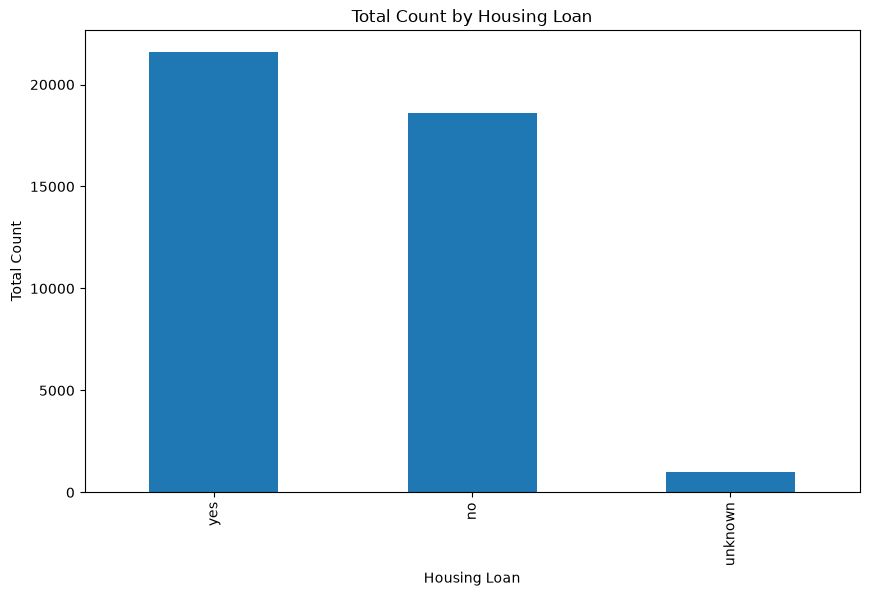

In [90]:
sorted_total_housing_loan_subscriptions.plot(kind='bar',figsize=(10,6))
plt.ylabel('Total Count')
plt.xlabel('Housing Loan')
plt.title('Total Count by Housing Loan')
plt.show()

In [91]:
housing_subscription_rate = pd.crosstab(data['housing_loan'],
                                    data['subscribed'],
                                    normalize='index'
                                   ) ['yes'] * 100
sorted_housing_subscription_rate = housing_subscription_rate.sort_values(ascending=False)
sorted_housing_subscription_rate

housing_loan
yes        11.619392
no         10.879605
unknown    10.808081
Name: yes, dtype: float64

In [92]:
subscribing_by(data,'housing_loan')

subscribed,total,yes,rate,vs_baseline
housing_loan,,,,
yes,21576,2507,11.6,0.3
no,18622,2026,10.9,-0.4
unknown,990,107,10.8,-0.5


In [93]:
personal_loan_subscriptions = pd.crosstab(data['personal_loan'],data['subscribed'])
personal_loan_subscriptions

subscribed,no,yes
personal_loan,,
no,30100,3850
unknown,883,107
yes,5565,683


In [94]:
total_personal_loan_subscriptions = data.groupby('personal_loan')['subscribed'].count()
sorted_total_personal_loan_subscriptions = total_personal_loan_subscriptions.sort_values(ascending=False)
sorted_total_personal_loan_subscriptions

personal_loan
no         33950
yes         6248
unknown      990
Name: subscribed, dtype: int64

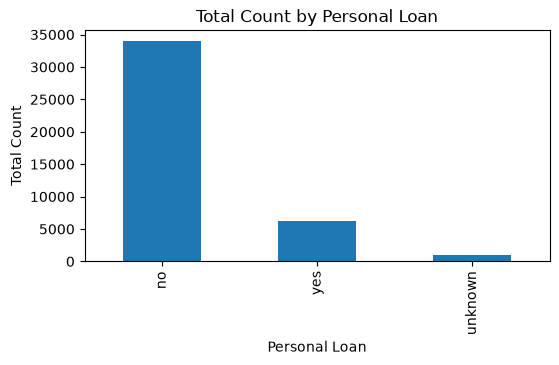

In [95]:
sorted_total_personal_loan_subscriptions.plot(kind='bar',figsize=(6,3))
plt.ylabel('Total Count')
plt.xlabel('Personal Loan')
plt.title('Total Count by Personal Loan')
plt.show()

In [96]:
personal_subscription_rate = pd.crosstab(data['personal_loan'],
                                    data['subscribed'],
                                    normalize='index'
                                   ) ['yes'] * 100
personal_subscription_rate = personal_subscription_rate.sort_values(ascending=False)
personal_subscription_rate

personal_loan
no         11.340206
yes        10.931498
unknown    10.808081
Name: yes, dtype: float64

In [97]:
subscribing_by(data,'personal_loan')

subscribed,total,yes,rate,vs_baseline
personal_loan,,,,
no,33950,3850,11.3,0.0
yes,6248,683,10.9,-0.4
unknown,990,107,10.8,-0.5


### Loans conclusion
Having a housing loan or personal loan makes almost no difference to subscribing: every group is within 0.5 points of the 11.3% baseline. So the bank shouldn’t use loan status to decide who to call, because loan status changes the rate by at most 0.5 points, while job changes it by up to 20 points, so job is a far better way to choose who to call.

In [98]:
# For each education category, how many subscribed and how many did not?

education_subscription_count = pd.crosstab(data['education'],data['subscribed'])
education_subscription_count

subscribed,no,yes
education,,
basic education - 4 years,3748,428
basic education - 6 years,2104,188
basic education - 9 years,5572,473
high school / secondary education,8484,1031
illiterate,14,4
professional / vocational course,4648,595
university degree,10498,1670
unknown,1480,251


In [99]:
# Which education categories had the most clients contacted overall?
total_contacted_per_education = data.groupby('education')['subscribed'].count()
sorted_total_contacted_per_education = total_contacted_per_education.sort_values(ascending=False)
sorted_total_contacted_per_education

education
university degree                    12168
high school / secondary education     9515
basic education - 9 years             6045
professional / vocational course      5243
basic education - 4 years             4176
basic education - 6 years             2292
unknown                               1731
illiterate                              18
Name: subscribed, dtype: int64

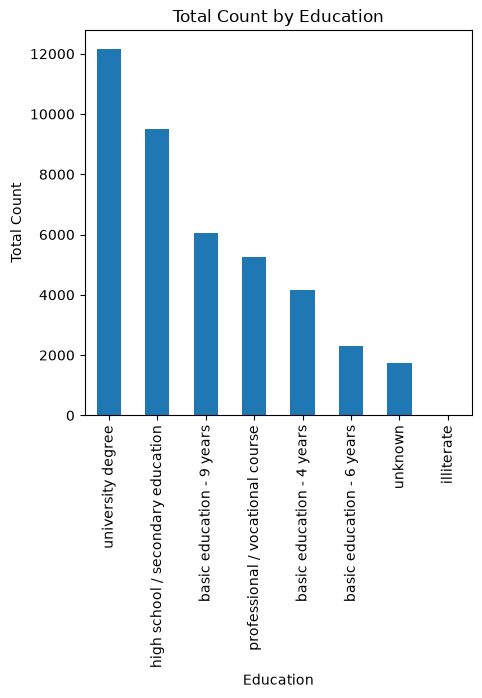

In [100]:
sorted_total_contacted_per_education.plot(kind='bar',figsize=(5,5))
plt.ylabel('Total Count')
plt.xlabel('Education')
plt.title("Total Count by Education")
plt.show()

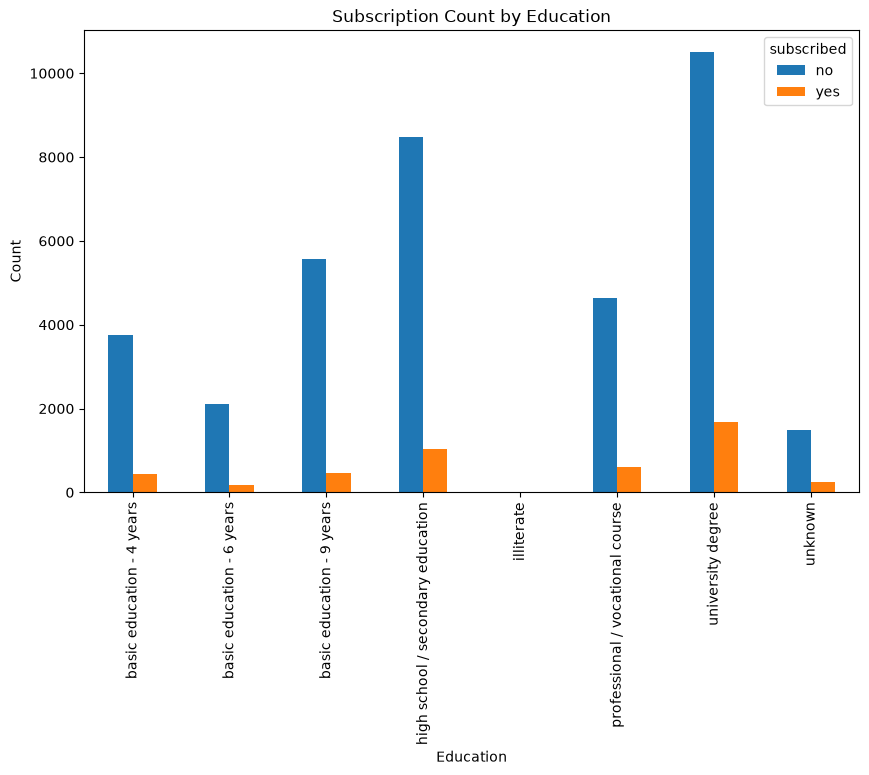

In [101]:
education_subscription_count.plot(kind='bar', figsize=(10,6))
plt.ylabel('Count')
plt.xlabel('Education')
plt.title("Subscription Count by Education")
plt.show()

In [102]:
# Of the clients in each job category, what percentage subscribed?
education_subscription_rate = pd.crosstab(data['education'],
                                    data['subscribed'],
                                    normalize='index'
                                   )['yes'] * 100
education_subscription_rate

education
basic education - 4 years            10.249042
basic education - 6 years             8.202443
basic education - 9 years             7.824648
high school / secondary education    10.835523
illiterate                           22.222222
professional / vocational course     11.348465
university degree                    13.724523
unknown                              14.500289
Name: yes, dtype: float64

In [103]:
# Does subscription rate differ across job categories?

sorted_education_subscription_rate = education_subscription_rate.sort_values( ascending=False)
sorted_education_subscription_rate

education
illiterate                           22.222222
unknown                              14.500289
university degree                    13.724523
professional / vocational course     11.348465
high school / secondary education    10.835523
basic education - 4 years            10.249042
basic education - 6 years             8.202443
basic education - 9 years             7.824648
Name: yes, dtype: float64

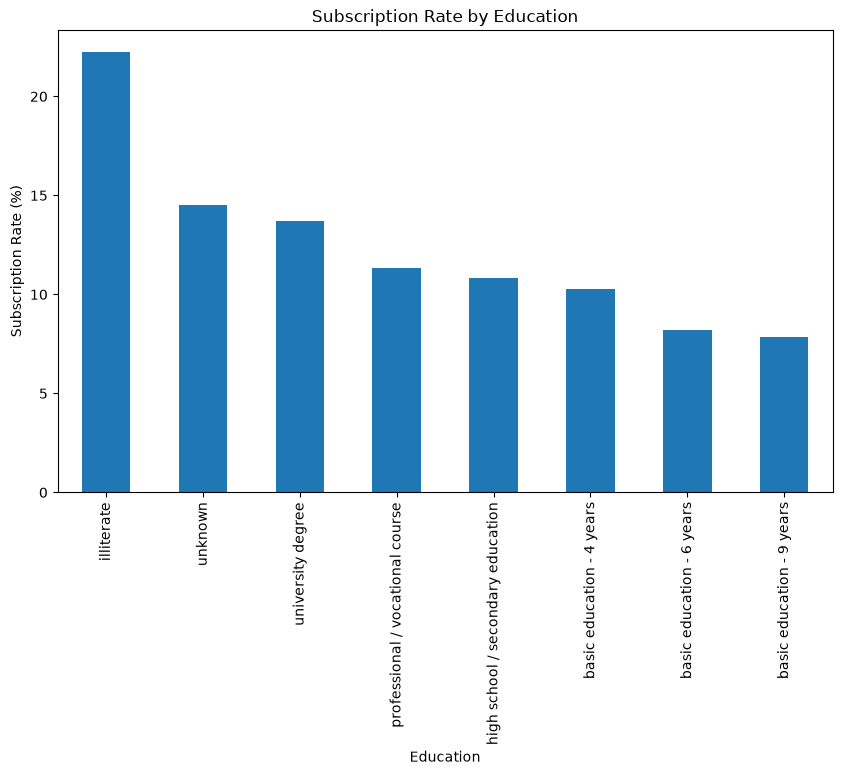

In [104]:
sorted_education_subscription_rate.plot(kind='bar', figsize=(10,6))
plt.ylabel('Subscription Rate (%)')
plt.xlabel('Education')
plt.title("Subscription Rate by Education")
plt.show()

In [105]:
subscribing_by(data,'education')

subscribed,total,yes,rate,vs_baseline
education,,,,
illiterate,18,4,22.2,10.9
unknown,1731,251,14.5,3.2
university degree,12168,1670,13.7,2.4
professional / vocational course,5243,595,11.3,0.0
high school / secondary education,9515,1031,10.8,-0.5
basic education - 4 years,4176,428,10.2,-1.1
basic education - 6 years,2292,188,8.2,-3.1
basic education - 9 years,6045,473,7.8,-3.5


In [106]:
pd.crosstab(data['education'],data['job'],margins=True)

job,admin,blue-collar,entrepreneur,housemaid,management,retired,self-employed,services,student,technician,unemployed,unknown,All
education,,,,,,,,,,,,,
basic education - 4 years,77,2318,137,474,100,597,93,132,26,58,112,52,4176
basic education - 6 years,151,1426,71,77,85,75,25,226,13,87,34,22,2292
basic education - 9 years,499,3623,210,94,166,145,220,388,99,384,186,31,6045
high school / secondary education,3329,878,234,174,298,276,118,2682,357,873,259,37,9515
illiterate,1,8,2,1,0,3,3,0,0,0,0,0,18
professional / vocational course,363,453,135,59,89,241,168,218,43,3320,142,12,5243
university degree,5753,94,610,139,2063,285,765,173,170,1809,262,45,12168
unknown,249,454,57,42,123,98,29,150,167,212,19,131,1731
All,10422,9254,1456,1060,2924,1720,1421,3969,875,6743,1014,330,41188


In [107]:
age_dist_that_subscribe = data[data['subscribed'] == 'yes']['age']
age_dist_that_subscribe

75       41
83       49
88       49
129      41
139      45
         ..
41174    62
41178    62
41181    37
41183    73
41186    44
Name: age, Length: 4640, dtype: int64

In [108]:
age_dist_that_dont_subscribe = data[data['subscribed'] == 'no']['age']
age_dist_that_dont_subscribe

0        56
1        57
2        37
3        40
4        56
         ..
41180    36
41182    29
41184    46
41185    56
41187    74
Name: age, Length: 36548, dtype: int64

In [109]:
average_age_that_subscribe = age_dist_that_subscribe.mean().round()
average_age_that_subscribe

np.float64(41.0)

In [110]:
average_age_that_dont_subscribe = age_dist_that_dont_subscribe.mean().round()
average_age_that_dont_subscribe

np.float64(40.0)

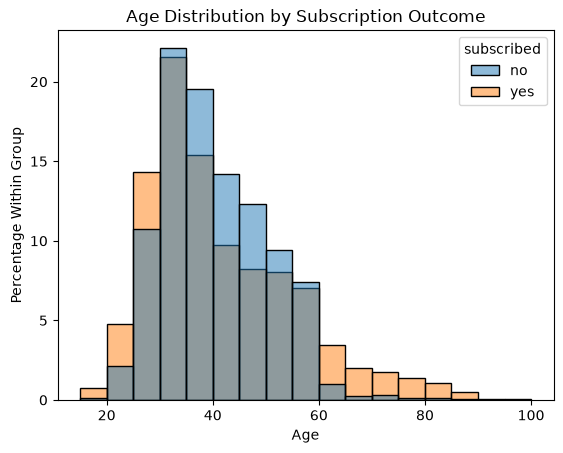

In [111]:
sns.histplot(
    data=data,
    x="age",
    hue="subscribed",
    bins=range(15,101,5),
    stat="percent",
    common_norm=False
)

plt.xlabel("Age")
plt.ylabel("Percentage Within Group")
plt.title("Age Distribution by Subscription Outcome")
plt.show()

In [112]:
subscribing_by(data, 'age_group', sort=False)

subscribed,total,yes,rate,vs_baseline
age_group,,,,
17-29,5669,922,16.3,5.0
30-39,16938,1715,10.1,-1.2
40-49,10526,834,7.9,-3.4
50-59,6862,697,10.2,-1.1
60+,1193,472,39.6,28.3


In [113]:
# Among people 60+, do retirees subscribe more than non-retirees the same age?
subscribing_by(data[data['age_group'] == '60+'], 'job')

subscribed,total,yes,rate,vs_baseline
job,,,,
housemaid,67,31,46.3,35.0
retired,785,334,42.5,31.2
admin,106,44,41.5,30.2
management,58,22,37.9,26.6
technician,49,15,30.6,19.3
unemployed,10,3,30.0,18.7
entrepreneur,17,5,29.4,18.1
unknown,29,8,27.6,16.3
blue-collar,43,8,18.6,7.3


In [114]:
# Among 17-29 year olds, do students subscribe more than non-students the same age?
subscribing_by(data[data['age_group'] == '17-29'], 'job')

subscribed,total,yes,rate,vs_baseline
job,,,,
unknown,25,9,36.0,24.7
student,682,228,33.4,22.1
unemployed,135,28,20.7,9.4
admin,1622,294,18.1,6.8
technician,802,122,15.2,3.9
management,181,27,14.9,3.6
self-employed,185,27,14.6,3.3
services,721,81,11.2,-0.1
housemaid,45,5,11.1,-0.2


### Age Group Conclusion

60+ subscribe at 39.6%, more than 3x the 11.3% baseline and 17 to 29 subscribe at 16.3% above 11.3% which gives us an idea of which group is better to target. The bank focused mostly on age groups from 30-39 which is at a 10.1% and 40-49 which is at a 7.9% which the bank shouldn't waste their time calling the most.

Does the job for age groups matter?

60+ age group jobs show better results toward admins(41.5%) and retirees(42.5%). housemaids(46%) was also one of them but with a total of 67 we would want stronger numbers to make a conclusion.

17 to 29 groups show students(33.4%) remain above the rest of the jobs. Unknown only had a total of 25 contacted which is again not strong enough to make a conclusion.

The bank should put their focus on age groups from 17 - 29 as Students (33.4%) subscribe nearly twice as often as admins the same age (18.1%) and anyone 60+ should be getting more calls to get more subscribers.

### Summary Findings

- previous successes 65.1%
  - The clients that said yes that were previously contacted showed us a 65.1% success, nearly 6x the 11.3% baseline, but they were only 1,373 of 41,188 calls. The bank should call them first.


- People 60+ subscribed at 39.6%, more than 3x the baseline. It's not just because most of them are retirees: admins over 60 (41.5%) subscribed almost the same as retirees over 60 (42.5%), so age is what matters. They only got 1,193 calls, so the bank should be calling more people 60+.

- Students subscribed at 31.4%. Even compared to people the same age (17-29), students (33.4%) subscribed nearly twice as often as admins (18.1%), so being a student matters on its own. Students should be getting more calls.
- the month pattern
  - May had the most calls (13,769) but the lowest rate (6.4%), while March, December, September and October were all above 40%. These months stayed strong even with people never contacted before (March 47.4% vs. May 5.5%), so the month matters on its own. The data can't explain why, since I removed the economic indicator columns.
- Housing and personal loans stayed within 0.5 points of the baseline, and single people only subscribed 1-3 points more than others the same age. The bank shouldn't use these to decide who to call.

In [117]:
data['subscribed_flag'] = (data['subscribed'] == 'yes').astype(int)
data.to_csv('EDA_bank_marketing.csv', index=False)